# Baseline Models (sprint 3)
Baselines for predicting whether a patient's CDR increases by the next visit (stable vs. declined).
This notebook covers **Model 2 (metadata-only)** from our project plan, plus a simple tabular MRI baseline that the CNN (Model 1) should beat. All results use patient-grouped 5-fold CV on the training set only; the test set is held out for final evaluation.

In [5]:
import sys
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
import wandb
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from src import config #for scoring
from src.models.evaluate import evaluate_model #for scoring

## Training data

In [8]:
# Load the ML ready dataset (one row per visit pair)
df = pd.read_csv(config.ML_READY_CSV)

#keep only training patients; the test set stays untouched until final eval
train = df[df["split"] == "train"]

#prints pairs and patients then how many declined
print(f"Training pairs: {len(train)} from {train['subject_id'].nunique()} patients")
print(f"Declined: {train['declined'].sum()} ({train['declined'].mean():.1%})")


Training pairs: 178 from 119 patients
Declined: 25 (14.0%)


## Feature sets
- **metadata-only**: demographics, MMSE, CDR, brain volumes from the CSV, visit timing, change features (Model 2)
- **mri-measures (tabular)**: brain-volume measures only; a simple imaging baseline, not the CNN
- **combined**: metadata + our MRI scan measure

`asf` is dropped because it duplicates `etiv` (r = -0.99). (ASF is calculated from eTIV.A; ASF = 1/eTIV)

In [13]:
# Metadata features from config, minus asf (it is almost the same as etiv)
metadata = [c for c in config.METADATA_FEATURES if c != "asf"]

# The three groups of inputs we compare, matching our project plan
feature_sets = {
    # Model 2: everything from the clinical CSV
    "metadata-only": metadata,
    # Brain measures only (a simple stand-in until the CNN is ready)
    "mri-measures (tabular)": ["etiv", "nwbv", "nwbv_change_prev", "nwbv_rate_prev", "mri_csf_proxy"],
    # Metadata plus the MRI measure we computed from the raw scans
    "combined": metadata + config.MRI_SCAN_FEATURES,
}

## Models
The models named in our project plan, plus a dummy model that always predicts "stable" as the floor.
`class_weight="balanced"` makes the models pay more attention to the rare "declined" class (14% of pairs).

In [16]:
models = {
    # Floor: ignores the data and always predicts the most common class ("stable").
    # Every real model has to beat this to be useful.
    "dummy": DummyClassifier(strategy="prior"),

    # Logistic regression: scale features first, then fit a weighted sum.
    # class_weight="balanced" makes missing a "declined" patient cost more since only 14% of pairs declined.
    "logistic_regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),

    # Random forest: 300 decision trees vote.
    # min_samples_leaf=5 stops trees from memorizing single patients (our data is small).
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42),

    # Gradient boosting: small trees built one after another, each fixing the last one's mistakes.
    # max_depth=3 keeps each tree simple to avoid overfitting.
    "gradient_boosting": HistGradientBoostingClassifier(
        max_depth=3, class_weight="balanced", random_state=42),
}

## Results
Every model is trained and scored on every feature set, and each run is logged to Weights & Biases.

In [19]:
rows = []  # one row of scores per (feature set, model) combination

for set_name, features in feature_sets.items():
    for model_name, model in models.items():
        # Train and score with our shared function (patient-grouped 5-fold CV, training set only)
        scores = evaluate_model(model, features)
        rows.append({"feature_set": set_name, "model": model_name, **scores})

        # Log this run to our team's W&B project so everyone can see it
        run = wandb.init(entity="ds-capstone-group-5",
                         project="predicting-alzheimers-progression",
                         name=f"{model_name} | {set_name}",
                         group="baselines",
                         config={"model": model_name, "feature_set": set_name},
                         reinit=True)
        run.log(scores)
        run.finish()

# Put all scores in one table, rounded for readability
results = pd.DataFrame(rows).round(3)
results

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/christinadames/.netrc.
wandb: Currently logged in as: cdames3 (ds-capstone-group-5) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.85955
f1,0
pr_auc,0.13951
precision,0
recall,0


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.60112
f1,0.21978
pr_auc,0.18016
precision,0.15152
recall,0.4


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.67416
f1,0.19444
pr_auc,0.22493
precision,0.14894
recall,0.28


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.74157
f1,0.17857
pr_auc,0.19882
precision,0.16129
recall,0.2


...

accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.85955
f1,0
pr_auc,0.13951
precision,0
recall,0


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.57303
f1,0.17391
pr_auc,0.18121
precision,0.1194
recall,0.32


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.70225
f1,0.23188
pr_auc,0.25293
precision,0.18182
recall,0.32


accuracy,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
accuracy,0.74157
f1,0.2069
pr_auc,0.19118
precision,0.18182
recall,0.24


,feature_set,model,roc_auc,pr_auc,recall,precision,f1,accuracy
0,metadata-only,dummy,0.496,0.140,0.00,0.000,0.000,0.860
1,metadata-only,logistic_regression,0.578,0.180,0.40,0.152,0.220,0.601
2,metadata-only,random_forest,0.559,0.225,0.28,0.149,0.194,0.674
3,metadata-only,gradient_boosting,0.525,0.199,0.20,0.161,0.179,0.742
4,mri-measures (tabular),dummy,0.496,0.140,0.00,0.000,0.000,0.860
5,mri-measures (tabular),logistic_regression,0.603,0.176,0.64,0.182,0.283,0.545
6,mri-measures (tabular),random_forest,0.620,0.228,0.56,0.250,0.346,0.702
7,mri-measures (tabular),gradient_boosting,0.564,0.180,0.28,0.167,0.209,0.702
8,combined,dummy,0.496,0.140,0.00,0.000,0.000,0.860
9,combined,logistic_regression,0.562,0.181,0.32,0.119,0.174,0.573


## ROC-AUC comparison

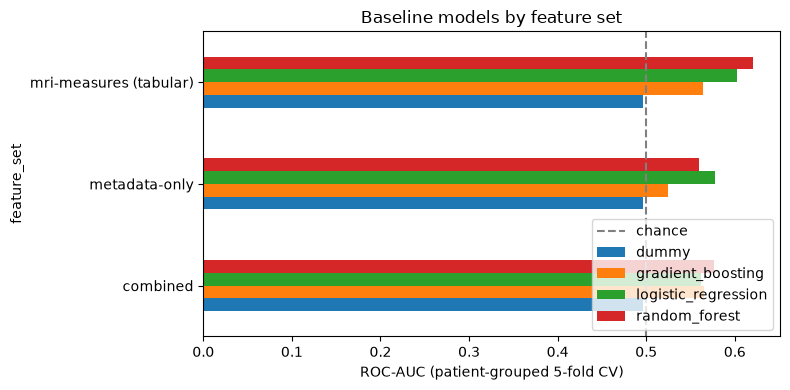

In [22]:
# One bar per model, grouped by feature set
results.pivot(index="feature_set", columns="model", values="roc_auc").plot.barh(figsize=(8, 4))

# Dashed line at 0.5 = random guessing; bars should be to the right of it
plt.axvline(0.5, color="gray", linestyle="--", label="chance")

# Labels
plt.xlabel("ROC-AUC (patient-grouped 5-fold CV)")
plt.title("Baseline models by feature set")
plt.legend(loc="lower right")
plt.tight_layout()

# Save for slides and the report, then show it here
plt.savefig("../reports/figures/15_baseline_comparison.png", dpi=150)
plt.show()

## Error analysis
Confusion matrix for the best model, and the patients who declined but got the lowest predicted risk (missed cases).

Best model: random_forest on mri-measures (tabular) (ROC-AUC 0.62)


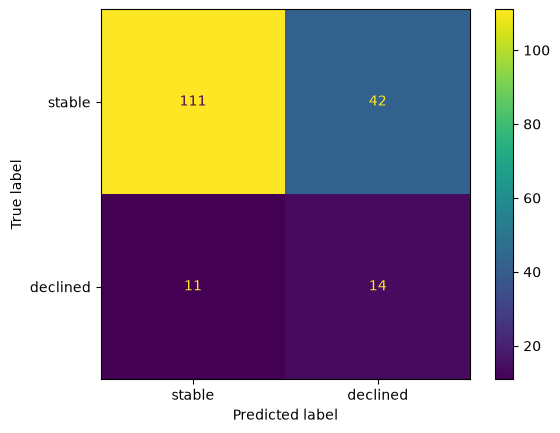

,subject_id,cdr,mmse,age,predicted_risk
207,OAS2_0176,0.0,30.0,87,0.03
21,OAS2_0018,0.0,29.0,88,0.09
51,OAS2_0041,0.0,28.0,73,0.12
178,OAS2_0145,0.0,30.0,68,0.13
57,OAS2_0046,0.5,20.0,83,0.17
148,OAS2_0118,0.0,30.0,67,0.35
35,OAS2_0031,0.0,30.0,88,0.35
119,OAS2_0092,0.0,28.0,83,0.36
143,OAS2_0114,0.5,27.0,76,0.40
22,OAS2_0020,0.0,29.0,80,0.41


In [29]:
# Pick the best real model (highest ROC-AUC, excluding dummy)
best = results[results["model"] != "dummy"].sort_values("roc_auc", ascending=False).iloc[0]
print(f"Best model: {best['model']} on {best['feature_set']} (ROC-AUC {best['roc_auc']})")

# Rerun that model with the same patient-grouped folds to get each pair's predicted risk
features = feature_sets[best["feature_set"]]
probs = cross_val_predict(models[best["model"]], train[features], train["declined"],
                          cv=PredefinedSplit(train["cv_fold"]), method="predict_proba")[:, 1]

# Confusion matrix: how many stable/declined pairs were predicted correctly vs. wrongly
ConfusionMatrixDisplay.from_predictions(train["declined"], (probs >= 0.5).astype(int),
                                        display_labels=["stable", "declined"])
plt.show()

# Patients who declined but the model gave the LOWEST risk (the ones it missed most badly)
missed = train.assign(predicted_risk=probs.round(2)).query("declined == 1")
missed.sort_values("predicted_risk")[["subject_id", "cdr", "mmse", "age", "predicted_risk"]].head(10)

## Save results

In [34]:
# Save the results table so it can be used in slides and the final report
results.to_csv("../reports/baseline_results.csv", index=False)
print("Saved reports/baseline_results.csv")

Saved reports/baseline_results.csv


## Findings
- Accuracy is misleading: the dummy model gets ~86% accuracy by never predicting decline, so we focus on recall, F1, and ROC-AUC.
- All baselines are only modestly above chance (best ROC-AUC ≈ .62 from random forest on mri measures). With only 25 declines in training, the signal is weak.
- Brain-volume measures did slightly worse compared with metadata alone, and combining them helped.
- Most missed cases start at CDR 0 with near-perfect MMSE, so their decline was not visible at the earlier visit.

## Next steps
- Model 1: CNN on raw MRI scans
- Model 3: CNN features + metadata
- Final evaluation of chosen models on the held-out test set